In [11]:
!mkdir -p data/processed results/figures
!wget -O data/processed/parkinsons_v1.csv https://raw.githubusercontent.com/KaiyoDev/Nhom_3_KhaiThacDuLieu_Parkinsons/main/data/processed/parkinsons_v1.csv

--2026-11-22 15:26:36--  https://raw.githubusercontent.com/KaiyoDev/Nhom_3_KhaiThacDuLieu_Parkinsons/main/data/processed/parkinsons_v1.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 75509 (74K) [text/plain]
Saving to: ‘data/processed/parkinsons_v1.csv’

data/processed/park 100%[===================>]  73.74K  --.-KB/s    in 0.01s   

2026-11-22 15:26:36 (5.56 MB/s) - ‘data/processed/parkinsons_v1.csv’ saved [75509/75509]



In [12]:
import datetime
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
SEED = 42

# 1. Đọc trực tiếp từ canonical CSV (bỏ files.upload() và file .xlsx)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CSV_PATH = ROOT / "data" / "processed" / "parkinsons_v1.csv"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

assert CSV_PATH.exists(), f"Không tìm thấy dữ liệu chuẩn tại: {CSV_PATH}"
df = pd.read_csv(CSV_PATH)
NGUON = "data/processed/parkinsons_v1.csv"

# Tách định danh và nhãn mục tiêu
if "name" in df.columns:
    df = df.drop(columns=["name"])

y = df["status"].copy()
X = df.drop(columns=["status"]).copy()

# Kiểm tra nghiêm ngặt không rò rỉ nhãn
assert "status" not in X.columns and "name" not in X.columns, "LỖI: nhãn/name lẫn vào input phân cụm!"
assert X.shape == (195, 22), f"Kích thước X không khớp (195, 22), nhận được: {X.shape}"
assert X.isna().sum().sum() == 0, "Dữ liệu vẫn còn giá trị khuyết (NaN)!"

print(f"Nguồn dữ liệu : {NGUON}")
print(f"Kích thước X  : {X.shape} | Phân bố nhãn status: {y.value_counts().to_dict()}")

# 2. Chuẩn hóa đặc trưng
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

# 3. Phân cụm K-Means (K = 2..10)
K_RANGE = list(range(2, 11))
labels_km = {}
km_rows = []

for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    km.fit(Xs)
    labels_km[k] = km.labels_
    sizes = sorted(np.bincount(km.labels_).tolist(), reverse=True)
    km_rows.append({
        "K": k,
        "inertia": round(float(km.inertia_), 1),
        "silhouette": round(float(silhouette_score(Xs, km.labels_)), 4),
        "kich_thuoc_cum": str(sizes),
        "ARI": round(float(adjusted_rand_score(y, km.labels_)), 4)
    })

km_table = pd.DataFrame(km_rows)
K_CHON = int(km_table.loc[km_table["silhouette"].idxmax(), "K"])
km_table["chon"] = np.where(km_table["K"] == K_CHON, "<--", "")

# 4. Phân cụm DBSCAN & Tìm điểm khuỷu tay (Knee point)
def knee_eps(Xm: np.ndarray, min_samples: int):
    nn = NearestNeighbors(n_neighbors=min_samples).fit(Xm)
    dists, _ = nn.kneighbors(Xm)
    kd = np.sort(dists[:, -1])
    t = np.arange(len(kd)) / (len(kd) - 1)
    v = (kd - kd.min()) / (kd.max() - kd.min())
    knee_val = float(kd[np.argmax(t - v)])
    return kd, knee_val

MS_LIST = [3, 5, 10]
kdist, knee = {}, {}
for ms in MS_LIST:
    kdist[ms], knee[ms] = knee_eps(Xs, ms)

MIN_SAMPLES = 5
EPS = round(knee[MIN_SAMPLES], 2)

labels_db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(Xs)
n_cum_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_nhieu = int((labels_db == -1).sum())
ari_db = round(float(adjusted_rand_score(y, labels_db)), 4)

mask_core = labels_db != -1
sil_db = round(float(silhouette_score(Xs[mask_core], labels_db[mask_core])), 4) if n_cum_db >= 2 else float("nan")

# Khảo sát lưới tham số DBSCAN
EPS_GRID = [1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0]
grid_rows = []
for ms in MS_LIST:
    eps_candidates = sorted(set(EPS_GRID + [round(knee[ms], 2)]))
    for eps_val in eps_candidates:
        lbl = DBSCAN(eps=eps_val, min_samples=ms).fit_predict(Xs)
        n_c = len(set(lbl)) - (1 if -1 in lbl else 0)
        n_n = int((lbl == -1).sum())
        sil_c = round(float(silhouette_score(Xs[lbl != -1], lbl[lbl != -1])), 4) if n_c >= 2 else float("nan")
        grid_rows.append({
            "min_samples": ms,
            "eps": eps_val,
            "is_knee": (eps_val == round(knee[ms], 2)),
            "so_cum": n_c,
            "so_nhieu": n_n,
            "silhouette_non_noise": sil_c,
            "ARI": round(float(adjusted_rand_score(y, lbl)), 4)
        })

grid_df = pd.DataFrame(grid_rows)

# Phân tích sự khác biệt đặc trưng giữa 2 cụm ở K=2
lab_best = labels_km[K_CHON]
nho = int(np.argmin(np.bincount(lab_best)))
Xs_df = pd.DataFrame(Xs, columns=X.columns)
chenh = (Xs_df[lab_best == nho].mean() - Xs_df[lab_best != nho].mean()).sort_values(ascending=False)

print("\n=== BẢNG KẾT QUẢ K-MEANS (K = 2..10) ===")
print(km_table.to_string(index=False))
print(f"\n=== KẾT QUẢ DBSCAN (min_samples={MIN_SAMPLES}) ===")
print(f"Knee raw = {knee[MIN_SAMPLES]:.4f} -> eps = {EPS} | Số cụm = {n_cum_db} | Nhiễu = {n_nhieu} | ARI = {ari_db}")
print(f"Khoảng ARI trên toàn lưới DBSCAN: [{grid_df['ARI'].min():.4f}, {grid_df['ARI'].max():.4f}]")

Nguồn dữ liệu : data/processed/parkinsons_v1.csv
Kích thước X  : (195, 22) | Phân bố nhãn status: {1: 147, 0: 48}

=== BẢNG KẾT QUẢ K-MEANS (K = 2..10) ===
 K  inertia  silhouette                        kich_thuoc_cum     ARI chon
 2   2817.2      0.4373                             [165, 30] -0.0978  <--
 3   2076.2      0.2763                         [106, 77, 12]  0.0582     
 4   1822.4      0.2358                       [91, 77, 23, 4]  0.0583     
 5   1595.5      0.2048                   [73, 64, 32, 22, 4]  0.1000     
 6   1442.0      0.2138               [60, 51, 30, 28, 22, 4]  0.1058     
 7   1319.8      0.2094            [54, 51, 31, 24, 23, 8, 4]  0.0882     
 8   1230.5      0.2201       [53, 35, 32, 23, 23, 15, 10, 4]  0.0313     
 9   1157.0      0.2265     [52, 39, 25, 24, 21, 13, 9, 8, 4]  0.0574     
10   1110.7      0.1896 [38, 35, 26, 23, 22, 18, 12, 9, 8, 4]  0.0481     

=== KẾT QUẢ DBSCAN (min_samples=5) ===
Knee raw = 3.3741 -> eps = 3.37 | Số cụm = 1 | Nhiễu =

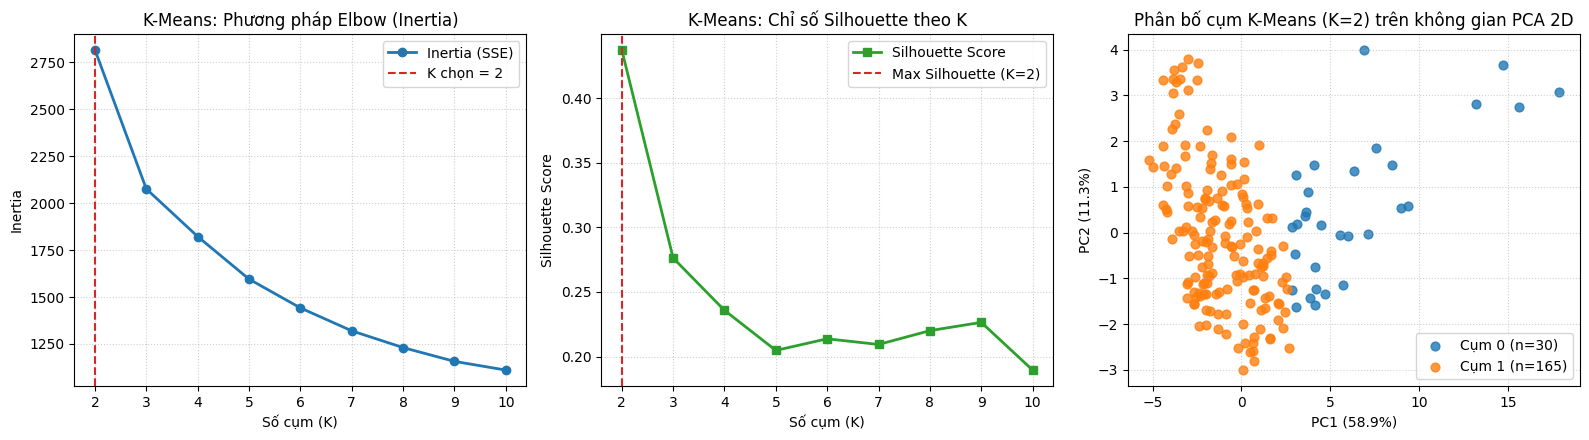

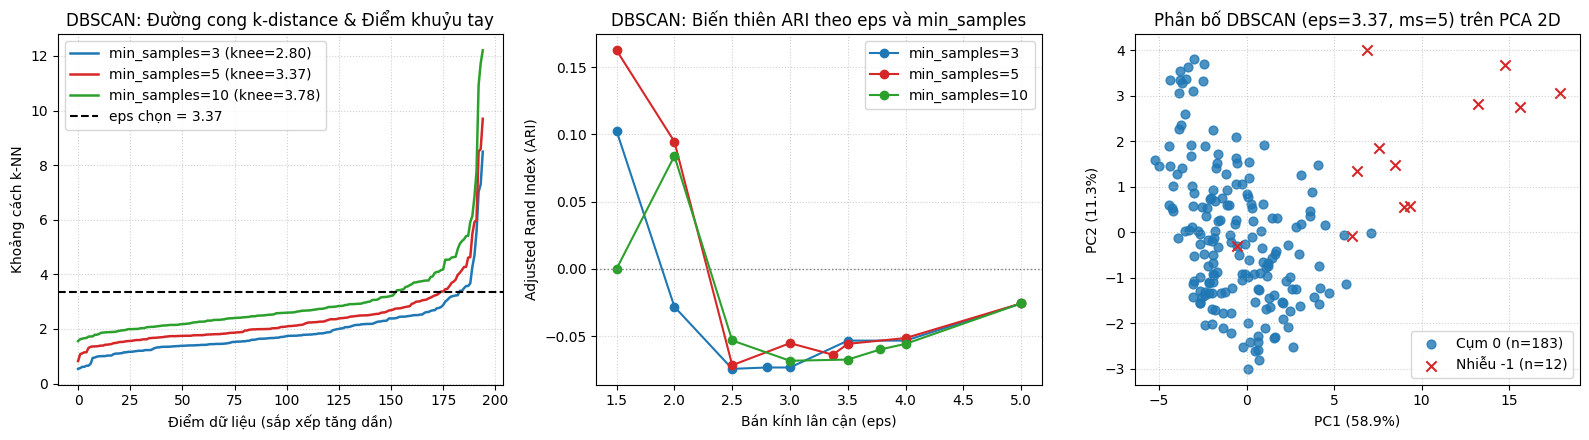

Đã lưu thành công các artifact:
 - results/m06_cluster_ari.csv
 - results/m06_dbscan_grid.csv
 - results/figures/m06_kmeans_selection.png
 - results/figures/m06_dbscan_analysis.png


In [13]:
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(Xs)
var_ratio = pca.explained_variance_ratio_ * 100

# Hình 1: Đánh giá K-Means
fig1, axes1 = plt.subplots(1, 3, figsize=(16, 4.5))

axes1[0].plot(km_table["K"], km_table["inertia"], marker="o", color="#1f77b4", linewidth=2, label="Inertia (SSE)")
axes1[0].axvline(K_CHON, color="#d62728", linestyle="--", label=f"K chọn = {K_CHON}")
axes1[0].set_title("K-Means: Phương pháp Elbow (Inertia)")
axes1[0].set_xlabel("Số cụm (K)")
axes1[0].set_ylabel("Inertia")
axes1[0].set_xticks(K_RANGE)
axes1[0].grid(True, linestyle=":", alpha=0.6)
axes1[0].legend()

axes1[1].plot(km_table["K"], km_table["silhouette"], marker="s", color="#2ca02c", linewidth=2, label="Silhouette Score")
axes1[1].axvline(K_CHON, color="#d62728", linestyle="--", label=f"Max Silhouette (K={K_CHON})")
axes1[1].set_title("K-Means: Chỉ số Silhouette theo K")
axes1[1].set_xlabel("Số cụm (K)")
axes1[1].set_ylabel("Silhouette Score")
axes1[1].set_xticks(K_RANGE)
axes1[1].grid(True, linestyle=":", alpha=0.6)
axes1[1].legend()

for cid, cname, color in [(0, "Cụm 0", "#1f77b4"), (1, "Cụm 1", "#ff7f0e")]:
    idx = (labels_km[K_CHON] == cid)
    axes1[2].scatter(X_pca[idx, 0], X_pca[idx, 1], label=f"{cname} (n={idx.sum()})", alpha=0.8, s=40, color=color)
axes1[2].set_title(f"Phân bố cụm K-Means (K={K_CHON}) trên không gian PCA 2D")
axes1[2].set_xlabel(f"PC1 ({var_ratio[0]:.1f}%)")
axes1[2].set_ylabel(f"PC2 ({var_ratio[1]:.1f}%)")
axes1[2].grid(True, linestyle=":", alpha=0.6)
axes1[2].legend()

plt.tight_layout()
fig1_path = FIGURES_DIR / "m06_kmeans_selection.png"
fig1.savefig(fig1_path, dpi=150, bbox_inches="tight")
plt.show()

# Hình 2: Phân tích DBSCAN
fig2, axes2 = plt.subplots(1, 3, figsize=(16, 4.5))

for ms, col in zip(MS_LIST, ["#1f77b4", "#d62728", "#2ca02c"]):
    axes2[0].plot(kdist[ms], label=f"min_samples={ms} (knee={knee[ms]:.2f})", color=col, linewidth=1.8)
axes2[0].axhline(EPS, color="black", linestyle="--", label=f"eps chọn = {EPS}")
axes2[0].set_title("DBSCAN: Đường cong k-distance & Điểm khuỷu tay")
axes2[0].set_xlabel("Điểm dữ liệu (sắp xếp tăng dần)")
axes2[0].set_ylabel("Khoảng cách k-NN")
axes2[0].grid(True, linestyle=":", alpha=0.6)
axes2[0].legend()

for ms, col in zip(MS_LIST, ["#1f77b4", "#d62728", "#2ca02c"]):
    sub = grid_df[grid_df["min_samples"] == ms].sort_values("eps")
    axes2[1].plot(sub["eps"], sub["ARI"], marker="o", label=f"min_samples={ms}", color=col)
axes2[1].axhline(0, color="gray", linestyle=":", linewidth=1)
axes2[1].set_title("DBSCAN: Biến thiên ARI theo eps và min_samples")
axes2[1].set_xlabel("Bán kính lân cận (eps)")
axes2[1].set_ylabel("Adjusted Rand Index (ARI)")
axes2[1].grid(True, linestyle=":", alpha=0.6)
axes2[1].legend()

inlier_mask = (labels_db != -1)
noise_mask = (labels_db == -1)
axes2[2].scatter(X_pca[inlier_mask, 0], X_pca[inlier_mask, 1], c="#1f77b4", label=f"Cụm 0 (n={inlier_mask.sum()})", alpha=0.8, s=40)
axes2[2].scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1], c="#d62728", marker="x", label=f"Nhiễu -1 (n={noise_mask.sum()})", s=55)
axes2[2].set_title(f"Phân bố DBSCAN (eps={EPS}, ms={MIN_SAMPLES}) trên PCA 2D")
axes2[2].set_xlabel(f"PC1 ({var_ratio[0]:.1f}%)")
axes2[2].set_ylabel(f"PC2 ({var_ratio[1]:.1f}%)")
axes2[2].grid(True, linestyle=":", alpha=0.6)
axes2[2].legend()

plt.tight_layout()
fig2_path = FIGURES_DIR / "m06_dbscan_analysis.png"
fig2.savefig(fig2_path, dpi=150, bbox_inches="tight")
plt.show()

# Xuất artifact CSV chuẩn vào results/
db_row = pd.DataFrame([{
    "K": f"DBSCAN(eps={EPS},ms={MIN_SAMPLES})",
    "inertia": np.nan,
    "silhouette": sil_db,
    "kich_thuoc_cum": f"[{int(inlier_mask.sum())}] (nhiễu: {n_nhieu})",
    "ARI": ari_db,
    "chon": "DBSCAN"
}])

export_ari_df = pd.concat([km_table, db_row], ignore_index=True)
export_ari_df["data_source"] = NGUON
export_ari_df["seed"] = SEED
export_ari_df["date"] = datetime.date.today().isoformat()
export_ari_df["python_libs"] = f"sklearn={sklearn.__version__};pandas={pd.__version__};numpy={np.__version__}"

ari_csv_path = RESULTS_DIR / "m06_cluster_ari.csv"
grid_csv_path = RESULTS_DIR / "m06_dbscan_grid.csv"

export_ari_df.to_csv(ari_csv_path, index=False, encoding="utf-8-sig")
grid_df.to_csv(grid_csv_path, index=False, encoding="utf-8-sig")

print("Đã lưu thành công các artifact:")
print(f" - {ari_csv_path.relative_to(ROOT)}")
print(f" - {grid_csv_path.relative_to(ROOT)}")
print(f" - {fig1_path.relative_to(ROOT)}")
print(f" - {fig2_path.relative_to(ROOT)}")